# How warm was the sea around Greece? 🌊
### Copernicus Climate Change Service · ERA5 · free account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/greece_sea_heat.ipynb)

In summer 2026 the seas around Greece were warmer than the 1991–2020 average on every day from June to September.
This notebook maps one day, **21 July 2026**, when the seas around Greece were on average about 2 °C warmer than normal,
using **ERA5**, the Copernicus reanalysis produced by ECMWF.

*In Google Colab? Press **Runtime → Run all**. The Climate Data Store queues requests, so step 2 can take a few minutes.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open too, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the dataset page and accept its licence (Download tab, bottom of the page). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.
   It is kept only for this Colab session and is not saved in the notebook.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks for it in a hidden box and saves it to `~/.cdsapirc` on the machine running the notebook (in Colab that is a temporary machine, wiped when you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook or screenshot that shows it. On your own computer with a `~/.cdsapirc` already in place, the cell uses that and asks nothing.

In [2]:
import os
from getpass import getpass
if not os.path.exists(os.path.expanduser("~/.cdsapirc")):
    key = getpass("Copernicus API key: ")
    for url, rc in (("https://cds.climate.copernicus.eu/api", "~/.cdsapirc"),
                    ("https://ads.atmosphere.copernicus.eu/api", "~/.adsapirc")):
        with open(os.path.expanduser(rc), "w") as f:
            f.write(f"url: {url}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the day and the area

In [4]:
AREA  = [43.5, 13.0, 30.5, 36.5]          # north, west, south, east: Ionian, Aegean, Cretan and Libyan Seas
YEAR, MONTH, DAY = "2026", "07", "21"
NORMAL = [str(y) for y in range(1991, 2021)]  # the WMO 30-year baseline
CITIES = [("Athens", 37.984, 23.728), ("Heraklion", 35.339, 25.144), ("Rhodes", 36.434, 28.217), ("Patras", 38.246, 21.735)]

## 2 · Get the sea surface temperature

One field for the day, and the July average of each year from 1991 to 2020 from the *monthly means* dataset.

In [5]:
day = ekd.from_source("cds", "reanalysis-era5-single-levels", {
    "product_type": "reanalysis", "variable": "sea_surface_temperature",
    "year": YEAR, "month": MONTH, "day": DAY, "time": "12:00", "area": AREA}).to_xarray()
normal = ekd.from_source("cds", "reanalysis-era5-single-levels-monthly-means", {
    "product_type": "monthly_averaged_reanalysis", "variable": "sea_surface_temperature",
    "year": NORMAL, "month": MONTH, "time": "00:00", "area": AREA}).to_xarray()

sst_day = day["sst"].squeeze()
tdim = [d for d in normal["sst"].dims if d not in ("latitude", "longitude")]
sst_normal = normal["sst"].mean(tdim)
anomaly = (sst_day - sst_normal.values).squeeze()
print(f"Average sea temperature in the box: {float(sst_day.mean()) - 273.15:.1f} °C, "
      f"{float(anomaly.mean()):+.1f} °C compared with July 1991–2020")

Average sea temperature in the box: 28.0 °C, +2.5 °C compared with July 1991–2020


## 3 · Map it

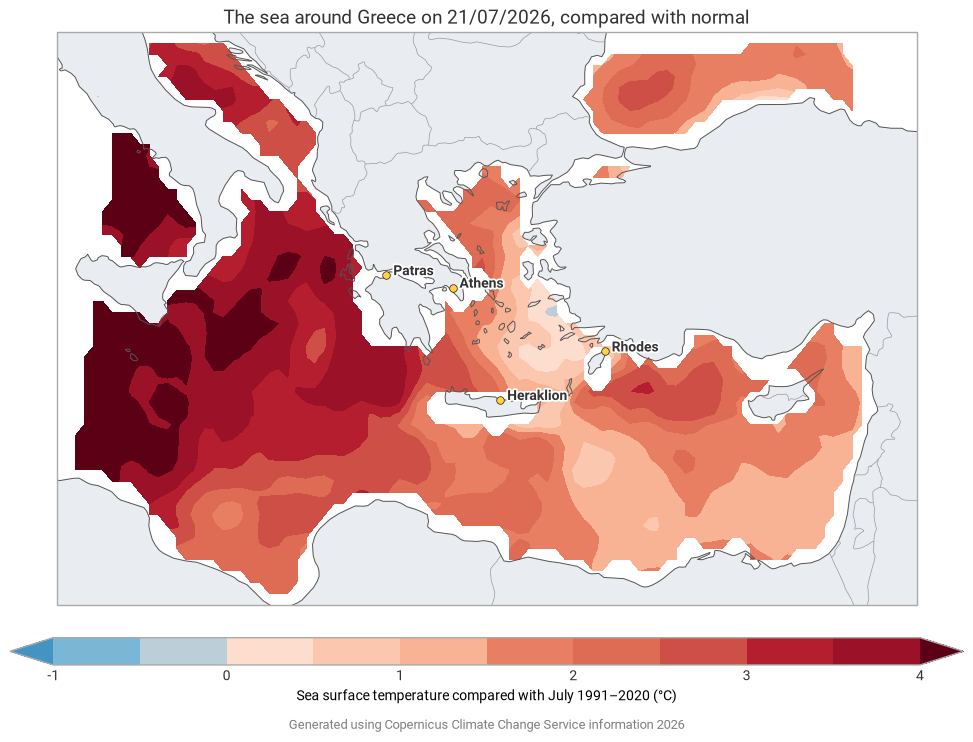

In [6]:
# blue below normal, white-to-red above it (white sits at 0)
colors = ["#4393c3", "#92c5de", "#fde0d2", "#fbbfa3", "#f4a582", "#e7785c", "#d6604d", "#b2182b", "#8c0d25", "#5c0016"]
style = ekp.styles.Style(levels=[-1, -0.5, 0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4], colors=colors, extend="both")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(12, 7))
chart.contourf(anomaly, style=style)
chart.land(color="#e9ecf1"); chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.5)
for name, la, lo in CITIES:
    chart.scatter(x=[lo], y=[la], s=30, color="#ffd23f", edgecolors="#1a1a1a", zorder=10)
    chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                  path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
chart.legend(label="Sea surface temperature compared with July 1991–2020 (°C)")
chart.title(f"The sea around Greece on {DAY}/{MONTH}/{YEAR}, compared with normal", fontsize=14)
chart.attribution("Generated using Copernicus Climate Change Service information 2026")
chart.save("greece_sea_heat.png")
chart.show()

## 4 · Your turn 🌍

- **Another day:** change `MONTH` and `DAY`, for example `"08"`, `"16"` (the coolest spell of the summer).
- **The Meltemi signature:** look at the eastern Aegean near the Turkish coast. Strong northerly winds pull cooler water up
  from below, so it often stays close to normal while the rest of the sea is warm.
- **Absolute temperature:** plot `sst_day - 273.15` instead of `anomaly` to see the sea in °C.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0 for these datasets). Credit:
*Generated using Copernicus Climate Change Service / Atmosphere Monitoring Service information [year].*
ECMWF runs both services for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)